# 3 Environment setup

In [ ]:
!pip install qiskit
!pip install qiskit-machine-learning


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 15.8 MB/s eta 0:00:00


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import SVC

from qiskit.circuit.library import zz_feature_map
from qiskit.primitives import StatevectorSampler as Sampler

from qiskit_machine_learning.datasets import ad_hoc_data
from qiskit_machine_learning.state_fidelities import ComputeUncompute
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.utils import algorithm_globals

algorithm_globals.random_seed = 12345

# 4 Part I — Generate and explore the dataset

In [33]:
adhoc = ad_hoc_data(20, 5, 2, 0.3)

print(adhoc)

(array([[3.51858377, 2.38761042],
       [1.25663706, 5.59203492],
       [2.82743339, 4.90088454],
       [5.27787566, 0.75398224],
       [3.20442451, 0.43982297],
       [3.20442451, 1.13097336],
       [3.64424748, 1.57079633],
       [3.33008821, 2.26194671],
       [6.22035345, 1.00530965],
       [1.63362818, 2.136283  ],
       [6.09468975, 2.38761042],
       [6.22035345, 5.46637122],
       [4.96371639, 1.75929189],
       [5.40353936, 4.20973416],
       [3.01592895, 4.96371639],
       [1.82212374, 3.64424748],
       [2.89026524, 3.83274304],
       [3.01592895, 4.46106157],
       [6.09468975, 2.19911486],
       [0.25132741, 0.06283185],
       [0.43982297, 1.13097336],
       [4.39822972, 1.38230077],
       [1.19380521, 4.52389342],
       [4.64955713, 3.0787608 ],
       [1.38230077, 5.15221195],
       [0.43982297, 4.0212386 ],
       [5.46637122, 5.59203492],
       [4.1469023 , 6.03185789],
       [2.26194671, 5.27787566],
       [5.40353936, 3.83274304],
       [0

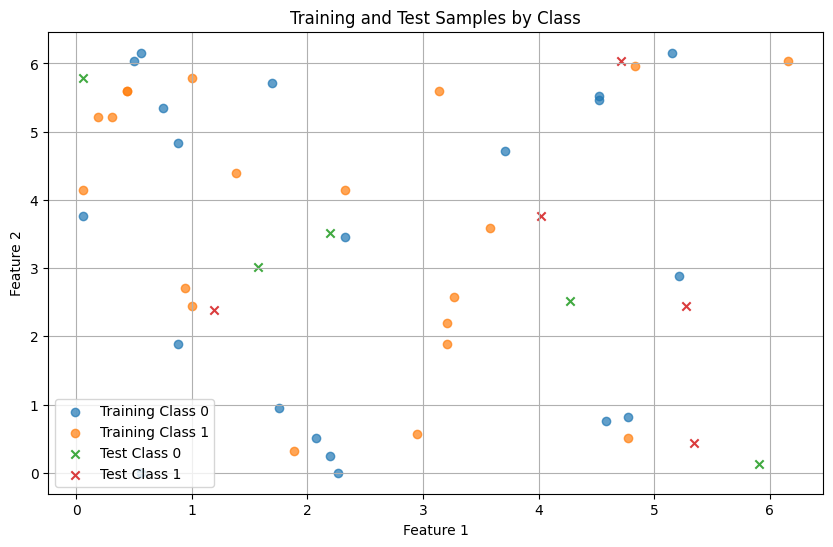

In [14]:
training_features, training_labels, test_features, test_labels = adhoc

training_labels_classes = np.argmax(training_labels, axis=1)
test_labels_classes = np.argmax(test_labels, axis=1)

plt.figure(figsize=(10, 6))

plt.scatter(training_features[training_labels_classes == 0, 0], training_features[training_labels_classes == 0, 1], label='Training Class 0', marker='o', alpha=0.7)
plt.scatter(training_features[training_labels_classes == 1, 0], training_features[training_labels_classes == 1, 1], label='Training Class 1', marker='o', alpha=0.7)

plt.scatter(test_features[test_labels_classes == 0, 0], test_features[test_labels_classes == 0, 1], label='Test Class 0', marker='x', alpha=0.9)
plt.scatter(test_features[test_labels_classes == 1, 0], test_features[test_labels_classes == 1, 1], label='Test Class 1', marker='x', alpha=0.9)

plt.title('Training and Test Samples by Class')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True)
plt.show()

# Questions

1/ The shape of the training feature matrix is 40x2.

2/ The shape of the test feature matrix is 10x2.

3/ The range of the two input features is approximately from 0 to 6 for both features.

4/ Based on the plot, the two classes are not linearly separable. It's not possible to draw a single straight line that perfectly separates them.

5/ A linear classifier applied directly to these original features would likely perform poorly. Since the classes are not linearly separable, a linear model would struggle to find an effective decision boundary, resulting in low accuracy and high misclassification rates.

6/  A kernel method would be very useful for this dataset because it can implicitly map the data into a higher-dimensional feature space where the classes might become linearly separable.

# 5 Part II — Construct a quantum feature map

In [36]:
zz_feature = zz_feature_map(2, 2, entanglement='linear')
zz_feature.draw()

┌───┐┌───────────┐                                          ┌───┐»
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■──┤ H ├»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐├───┤»
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├┤ H ├»
   └───┘└───────────┘└───┘└──────────────────────────────┘└───┘└───┘»
«   ┌───────────┐                                          
«0: ┤ P(2*x[0]) ├──■────────────────────────────────────■──
«   ├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐
«1: ┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├
«   └───────────┘└───┘└──────────────────────────────┘└───┘

# Questions

1/ Two qubits are used.

2/ The classical features x[0] and x[1] enter the circuit as parameters for the single-qubit phase gates P(2*x[i]) and as parameters in the controlled phase gate P((-π + x[0])*(-π + x[1])*2). The input features are encoded into the rotation angles of these gates.

3/ The gates used are Hadamard gates (`H`), parameterized phase gates (`P`), and CNOT.

4/ The entanglement is introduced using the CNOT gates.

5/ First, it would increment the circuit depth making it more complicated. Then it would increase the number of rotations and possibly make a full rotation of the block's sphere and get back to square one.

# Part III — Build the quantum kernel

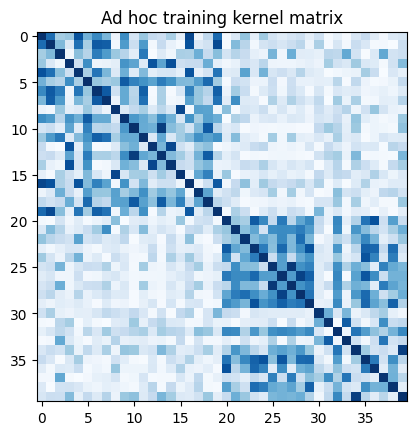

In [46]:
adhoc_kernel = FidelityQuantumKernel(feature_map=zz_feature, fidelity=ComputeUncompute(sampler=Sampler()))


adhoc_matrix_train = adhoc_kernel.evaluate(x_vec=training_features)
plt.imshow(
np.asmatrix(adhoc_matrix_train),
interpolation="nearest",
origin="upper",
cmap="Blues"
)
plt.title("Ad hoc training kernel matrix")
plt.show()

# Questions

1/ The dimension of Ktrain is 40x40

2/ Yes it is symmetric because the kernel function K(x_i, x_j) is a symmetric function. This means that the similarity between x_i and x_j is the same as the similarity between x_j and x_i.

3/ The diagonal element represents the similarity of a data point with itself in the feature space.

4/ A pair of points with larger kernel values indicates greater similarity between these points in the feature space induced by the kernel.

5/ A pair of points with smaller kernel values indicates lower similarity between these points in the feature space.

6/

#Part IV — Classification with a Support Vector Classifier
# (SVC)

In [57]:
svc_quantum = SVC(kernel=adhoc_kernel.evaluate)
#print(training_features)
svc_quantum.fit(training_features, training_labels_classes)

quantum_score = svc_quantum.score(test_features, test_labels_classes)
print(f"Quantum score for SVC: {quantum_score}")

Quantum score for SVC: 1.0


#Questions

1/ No it is not a quantum algorithm itself. It is a classical machine learning algorithm.

2/ It takes a kernel matrix and uses classical optimization techniques to find the optimal hyperplane that separates the classes in the feature space defined by the kernel.

3/ The quantum computation is used to generate the quantum kernel. In our case, the FidelityQuantumKernel uses the zz_feature_map.

4/ The score obtained on the test set for both the classical SVC with the quantum kernel was 1.0

5/ This score indicates a perfect classification on the test set. It suggests that the quantum feature map effectively transformed the original non-linearly separable data into a feature space where the two classes became perfectly separable.

In [56]:
qsvc = QSVC(quantum_kernel=adhoc_kernel)
qsvc.fit(training_features, training_labels_classes)

qsvc_score = qsvc.score(test_features, test_labels_classes)
print(f"Quantum score for QSVC: {qsvc_score}")

Quantum score for QSVC: 1.0
